In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.stats import gaussian_kde
from sklearn.decomposition import PCA
import scanpy as sc
import anndata
from noise_model import *
import torch
import pickle
import seaborn as sns

## Compute Unspliced/Spliced shift per Cell type

In [2]:
data = sc.read_h5ad('INPUT/scRNAseq/scRNAseq_full.h5ad')
data.obs.set_index('CellID', inplace=True)
annotation = pd.read_csv('INPUT/scRNAseq/theta_Zspace_annotation.csv').set_index('CellID')
new_obs = data.obs.merge(annotation,left_index= True, right_index=True, how = 'inner')
data = data[new_obs.index]
data.obs = new_obs
data.layers['spliced'] = data.layers['spliced'].todense()
data.layers['unspliced'] = data.layers['unspliced'].todense()
data = data[data.obs.Condition == 'ctrl']

/home/mleonard/miniconda3/envs/2_scvelo/lib/python3.8/site-packages/anndata/_core/anndata.py:1838: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [3]:
#Drop duplicates
data = data[~data.obs.index.duplicated(keep= 'first')]

# Drop extreme cells
data = data[data.layers['spliced'].sum(1) > np.percentile(data.layers['spliced'].sum(1), 2)]
data = data[data.layers['spliced'].sum(1) < np.percentile(data.layers['spliced'].sum(1), 98)]
data.var.index = data.var.index.str.upper()

# Drop genes with low U
U_not_null = data.layers['unspliced'].sum(axis = 0) > 5/100*data.shape[0]
data = data[:,U_not_null]

S_not_null = data.layers['spliced'].sum(axis = 0) > 5/100*data.shape[0]
data = data[:,S_not_null]



In [4]:

ectoderm = ['Neuroectoderm/NMPs', 'Early neuroectoderm/NMPs' ]
endoderm = ['Endoderm', 'Early endoderm' ]
mesoderm = [ 'Cardiac mesoderm', 'Early cardiac mesoderm', 'Early somitic mesoderm','Somitic mesoderm' ]
primitive_tissues = ['Epiblast','Ectopic pluripotency', 'Primitive streak' , 'Naive pluripotency']
porcn_cluster = ['Wnt. inh. state']

# Create an empty dictionary to store the mappings
germ_layers = {}

# Populate the dictionary with the mappings
for item in ectoderm:
    germ_layers[item] = 'Neuroectoderm/NMPs'

for item in endoderm:
    germ_layers[item] = 'Endoderm'

for item in mesoderm:
    germ_layers[item] = 'Mesoderm'

for item in primitive_tissues:
    germ_layers[item] = 'Early tissues'

for item in porcn_cluster:
    germ_layers[item] = 'Wnt. inhibitor'

data.obs['BIG_celltype'] = data.obs['Cell type'].map(germ_layers)

/tmp/ipykernel_1789631/3913244181.py:26: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  data.obs['BIG_celltype'] = data.obs['Cell type'].map(germ_layers)


In [5]:
def make_design_matrix(cell_identifiers):
    design_matrix = torch.hstack([(cell_identifiers == v).type(torch.int64).reshape(len(cell_identifiers), 
                                                              1) for i, v in enumerate(torch.unique(cell_identifiers))])
    return design_matrix


In [6]:
categ = 'BIG_celltype'
# Construct batch_design_matrix
regions = data.obs[categ].values.astype(str)
ids=torch.zeros(data.n_obs, dtype=torch.int64)
for i, v in enumerate(np.unique(regions)):
    ids[regions==v]=i
batch_design_matrix = make_design_matrix(ids)
S = data.layers['spliced']

# Construct S_frac
S_nUMI_per_cell = S.sum(axis=1) # sum over genes
S_frac = S / S_nUMI_per_cell[:,None]
data.layers['S_sz_full'] = S_frac
data.obs['n_scounts']=S_nUMI_per_cell
batch_design_matrix.shape

torch.Size([14682, 5])

## Fitting Fourier series to spliced/unspliced

In [7]:
# BIG cell type
samples = ['Mesoderm', 'Early tissues', 'Endoderm', 'Neuroectoderm/NMPs']

indexes = ["phi_x", "phi_y"]
nu_infos = []
nu_u_infos = []
for i, sam in enumerate(samples):
    print(sam)
    data_sample = data[data.obs[categ] == sam]
    phase = data_sample.obs['inferred_theta'].values
    
    print('Spliced')
    nu_sample = get_nus(data_sample, phase, 'Poisson')
    
    print('Unspliced')
    nu_u_sample = get_nus_unspliced(nu_sample[12], phase, 'Poisson' , nu_sample[13])
    
    nu_infos.append(nu_sample)
    nu_u_infos.append(nu_u_sample)
    
    

Mesoderm
Spliced
[0.30902229 0.03627356 0.34237688 ... 0.08787912 0.05296198 0.04839311]
Unspliced
Early tissues
Spliced
[0.30764675 0.06393629 0.00190278 ... 0.06925391 0.03098902 0.04466733]
Unspliced
Endoderm
Spliced
[0.40329968 0.08267287 0.34177549 ... 0.13098601 0.07019166 0.075763  ]
Unspliced
Neuroectoderm/NMPs
Spliced
[0.33084293 0.06222661 0.12463807 ... 0.06899895 0.06895995 0.06307509]
Unspliced


In [8]:

with open('INPUT/scRNAseq/Mine_BIG_celltype_s.pkl', 'wb') as file:
    pickle.dump(nu_infos, file)

with open('INPUT/scRNAseq/Mine_BIG_celltype_u.pkl', 'wb') as file:
    pickle.dump(nu_u_infos, file)
    

## Plots

In [10]:
with open('INPUT/scRNAseq/Mine_BIG_celltype_s.pkl', 'rb') as file:
    nu_infos = pickle.load(file)
with open('INPUT/scRNAseq/Mine_BIG_celltype_u.pkl', 'rb') as file:
    nu_u_infos = pickle.load(file)
    
# Mine  cell type
samples = ['Mesoderm', 'Early tissues', 'Endoderm', 'Neuroectoderm/NMPs']
DISPLAY_GROUPS = [ 'Early tissues', 'Mesoderm', 'Endoderm', 'Neuroectoderm/NMPs']
labels = [ 'Early tissues', 'Mesoderm', 'Endoderm', 'Neuroectoderm \n /NMPs']
palette = ['gold', 'lightskyblue','mediumseagreen', 'red']
name = 'Mine_celltype_ctrl'

DISPLAY_COLORS = palette

RANDOM_SEED = 1
# Half-life used in the period calculation
HALF_LIFE_HOURS = 1.25


# Output paths
CSV_DIR = 'FIGURES/'
PLOT_DIR = 'FIGURES/'

95 common genes across selected groups


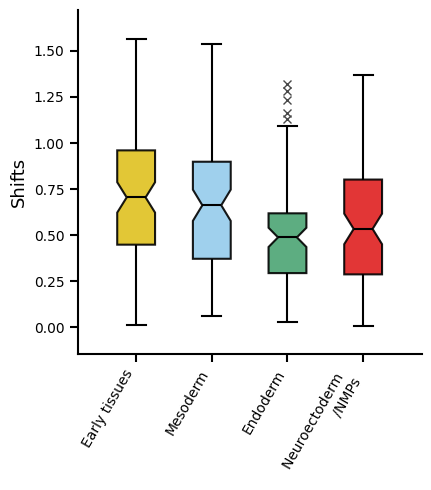

In [ ]:


idx_map = {s: i for i, s in enumerate(samples)}
sel_idx = [idx_map[s] for s in DISPLAY_GROUPS if s in idx_map]
if not sel_idx:
    raise ValueError("None of DISPLAY_GROUPS are present in `samples`.")

# Slice all inputs to the chosen groups only
samples_sel    = [samples[i] for i in sel_idx]
nu_infos_sel   = [nu_infos[i] for i in sel_idx]
nu_u_infos_sel = [nu_u_infos[i] for i in sel_idx]
palette_sel    = [DISPLAY_COLORS[DISPLAY_GROUPS.index(s)] for s in samples_sel]

# --- Step 0 (selected groups only): Shift calculations ---
shifts_sample_sel = [
    [
        get_angular_shift(u, s)
        for u, s in zip(
            nu_u_infos_sel[i][6][nu_u_infos_sel[i][10]],
            nu_infos_sel[i][6][nu_infos_sel[i][10]][nu_u_infos_sel[i][10]]
        )
    ]
    for i in range(len(samples_sel))
]

# --- Step 1 (selected groups only): Genes with shift in (0, pi/2) ---
gene_lists = [
    genes_with_shift_in_quadrant(u_sample, shifts_sample_sel[i])
    for i, u_sample in enumerate(nu_u_infos_sel)
]

# --- Step 2 (selected groups only): Intersection across selected samples ---
common_genes = intersect_gene_lists(gene_lists)
print(f"{len(common_genes)} common genes across selected groups")
if len(common_genes) == 0:
    raise ValueError("No common genes found in the specified shift range for selected groups.")

# --- Step 3 (selected groups only): Extract shifts for the common genes ---
commun_shifts = extract_common_shifts(nu_u_infos_sel, shifts_sample_sel, common_genes)
m = np.array(commun_shifts).T  # shape: (n_common_genes, n_selected_samples)
cs = pd.DataFrame(m, columns=samples_sel)

# --- Plot (selected groups only) ---
fig, ax = plt.subplots(figsize=(5, 5)) 

sns.boxplot(
    data=cs,
    width=0.50,                  
    notch=True,
    showcaps=True,
    palette=palette_sel,
    flierprops={"marker": "x"},
    boxprops={"alpha": 0.9, "linewidth": 1.5, "edgecolor": "black"},
    whiskerprops={"linewidth": 1.5, "color": "black"},
    capprops={"linewidth": 1.5, "color": "black"},
    medianprops={"linewidth": 1.5, "color": "black"},
    ax=ax,
)


ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)
ax.spines["left"].set_color("black")
ax.spines["bottom"].set_color("black")


ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=60, ha="right")   



ax.tick_params(axis="both", width=1.5, length=6, labelsize=12)


ax.tick_params(axis="y", width=1.5, length=6, labelsize=10)
ax.set_ylabel('Shifts',fontsize=13 )


ax.set_title("")


ax.margins(x=0.20, y=0.10)

try:
    ax.set_box_aspect(1)  
except Exception:
    ax.set_aspect('equal', adjustable='box')

plt.tight_layout()
outpath = PLOT_DIR + name + '_shift.png'
outpath_csv = CSV_DIR + name + '_shift.csv'

fig.savefig(outpath, dpi=400, bbox_inches='tight', transparent=True)
cs.to_csv(outpath_csv, index=False)

plt.show()


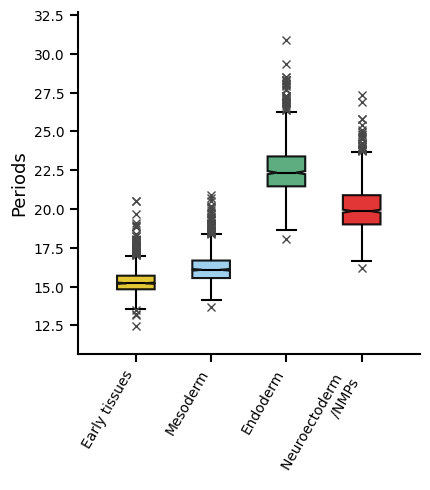

In [ ]:
# --- Bootstrap + period conversion (selected groups only) ---

rng = np.random.default_rng(RANDOM_SEED)
L = 1000  # number of bootstrap replicates


omega = bootstrap_first_pc_scale(m, n_boot=L, rng=rng)


with np.errstate(divide='ignore', invalid='ignore'):
    periods = 2 * np.pi / (omega / HALF_LIFE_HOURS)

df = pd.DataFrame(periods, columns=samples_sel)

# Plot using only selected groups/colors
fig, ax = plt.subplots(figsize=(5, 5)) 

sns.boxplot(
    data=df,
    width=0.50,                  
    notch=True,
    showcaps=True,
    palette=palette_sel,
    flierprops={"marker": "x"},
    boxprops={"alpha": 0.9, "linewidth": 1.5, "edgecolor": "black"},
    whiskerprops={"linewidth": 1.5, "color": "black"},
    capprops={"linewidth": 1.5, "color": "black"},
    medianprops={"linewidth": 1.5, "color": "black"},
    ax=ax,
)


ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)
ax.spines["left"].set_color("black")
ax.spines["bottom"].set_color("black")

ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=60, ha="right")   



ax.tick_params(axis="both", width=1.5, length=6, labelsize=12)

ax.tick_params(axis="y", width=1.5, length=6, labelsize=10)
ax.set_ylabel('Periods',fontsize=13 )


ax.set_title("")


ax.margins(x=0.20, y=0.10)


try:
    ax.set_box_aspect(1)  
except Exception:
    ax.set_aspect('equal', adjustable='box')

plt.tight_layout()

outpath = PLOT_DIR + name + '_periods.png'
outpath_csv = CSV_DIR + name + '_periods.csv'


fig.savefig(outpath, dpi=400, bbox_inches='tight', transparent=True)
cs.to_csv(outpath_csv, index=False)


plt.show()


